<a href="https://colab.research.google.com/github/ralph-Jung/AI-Class/blob/main/9%EC%A3%BC%EC%B0%A8/LSTM%EC%9D%84_%EC%9D%B4%EC%9A%A9%ED%95%9C_%EC%A3%BC%EA%B0%80_%EC%98%88%EC%B8%A1_(_%EB%8D%B0%EC%9D%B4%ED%84%B0%20%EB%88%84%EC%88%98%20%EB%B0%8F%20%EC%88%98%EC%A0%95_%EB%B2%84%EC%A0%84_).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install finance-datareader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [finance-datareader]


In [2]:
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM

In [3]:
# (2) 데이터셋 로드: 삼성전자(005930), 2016년 이후
samsung = fdr.DataReader('005930', '2016')
print(samsung)

openValues = samsung[['Open']].values

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-09  187200  195400  183800  187000  19855892 -0.033592
2026-11-10  199400  201500  196400  197300  15289184  0.055080
2026-11-11  197100  208500  196300  208000  16238236  0.054232
2026-11-12  208500  214000  206000  206500  19721557 -0.007212
2026-11-13  214000  216000  205000  209000  12822005  0.012107

[2664 rows x 6 columns]


In [4]:
# 먼저 원본 데이터를 시간 순서대로 나누기 (섞지 않음)
split = int(len(openValues) * 0.8)
train_raw = openValues[:split]
test_raw  = openValues[split:]

In [5]:
# (4) 정규화: 트레인으로만 fit, 테스트는 transform만 (데이터 누수 방지)
scaler = MinMaxScaler(feature_range=(0, 1))
train_data = scaler.fit_transform(train_raw)   # fit + transform
test_data  = scaler.transform(test_raw)

In [6]:
# (5) 순차 훈련 데이터 생성
def make_sample(data, window):
    train = []
    target = []
    for i in range(len(data) - window):
        train.append(data[i:i + window])
        target.append(data[i + window])
    return np.array(train), np.array(target)

X_train, y_train = make_sample(train_data, 30)

In [7]:
# (6) LSTM 구축
model = Sequential()
model.add(LSTM(16,
               input_shape=(X_train.shape[1], 1),
               activation='tanh',
               return_sequences=False)
          )
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [8]:
# (7) 모델 학습
model.compile(optimizer='adam', loss='mean_squared_error')
model.fit(X_train, y_train, epochs=100, batch_size=16)

Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0301
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0012
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.0749e-04
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.8936e-04
Epoch 5/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.7893e-04
Epoch 6/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.7583e-04
Epoch 7/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.5273e-04
Epoch 8/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.3092e-04
Epoch 9/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.5392e-04
Epoch 10/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.0883e-04
Epoch 11/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.0693e-04
Epoch 12/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.8633e-04
Epoch 13/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.7776e-04
Epoch 14/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.6571

In [9]:
# (8) 테스트 예측: 트레인 마지막 30일을 테스트 앞에 붙여서 테스트 전체 예측
test_input = np.concatenate([train_data[-30:], test_data])
X_test, y_test = make_sample(test_input, 30)
pred = model.predict(X_test)

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


In [10]:
# 0~1 값을 실제 가격(원)으로 되돌리기
pred_price   = scaler.inverse_transform(pred)
actual_price = scaler.inverse_transform(y_test)

In [11]:
# (9) 성능 평가: 단순 기준선(어제 값 = 오늘 예측)과 비교
naive_price = scaler.inverse_transform(test_input[30 - 1:-1])

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

print('LSTM  RMSE:', round(rmse(actual_price, pred_price)), '원')
print('Naive RMSE:', round(rmse(actual_price, naive_price)), '원')

LSTM  RMSE: 17816 원
Naive RMSE: 8704 원


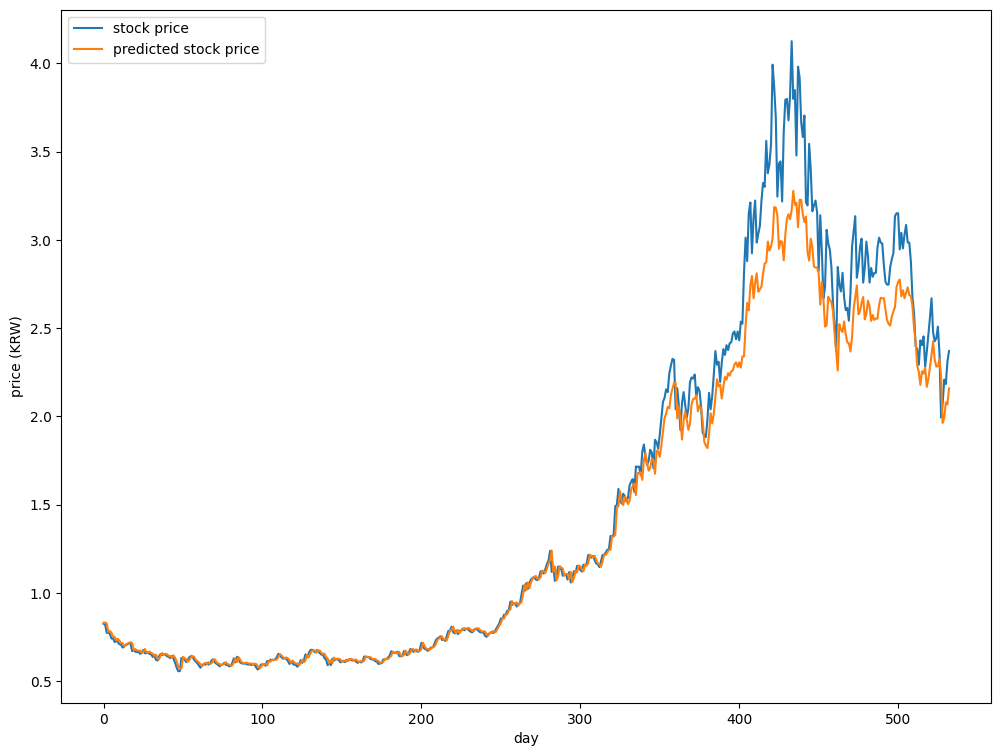

In [12]:
# (10) 그래프 그리기
plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.xlabel('day')
plt.ylabel('price (KRW)')
plt.legend()
plt.show()